In [152]:
import numpy as np
import scipy
import matplotlib.pyplot as plt


In [153]:
def eta_c_fit(Tt2,Tt4):
    x = Tt4/Tt2
    a = -2.3219 
    b = 1.7094 
    c = -0.2897 
    d = 0.0155
    return a + b*x + c*x**2 + d*x**3

def corr_rpm_fit(pi_c):
    x = pi_c
    aa = 22352.47 
    bb = 3718.445 
    cc = -52.5576 
    dd = -1.0899
    return aa + bb*x + cc*x**2 + dd*x**3

In [154]:
gamma = 1.4
Cp = 1004.5
R = 287
h = 4.45e+7

class given:
    M0 = 0.85
    T0 = 236.23 # K
    P0 = 35651 # Pa
    M2 = 0.5 
    A1 = 0.00318 # m^2
    A0 = A1
    
    pi_c = 14.43
    pi_b = 1.0
    pi_d = 0.989163
    eta_t = 0.90
    
    Tt4 = 1500 # K

# On Design

In [155]:
u = np.zeros(9)
P = np.zeros(9)
T = np.zeros(9)
M = np.zeros(9)
rho = np.zeros(9)
A = np.zeros(9)
Pt = np.zeros(9)
Tt = np.zeros(9)

## Farfield

In [156]:
M[0] = given.M0
T[0] = given.T0
P[0] = given.P0
rho[0] = P[0]/(R*T[0])
A[0] = given.A0

u[0] = M[0]*np.sqrt(gamma*R*T[0])

tau_r = 1+(gamma-1)/2 * M[0]**2
pi_r = tau_r**(gamma/(gamma-1))

Tt[0] = T[0] * tau_r
Pt[0] = P[0] * pi_r

m_dot = rho[0] * u[0] * A[0]
m_dot

pi_r

1.603818761435756

## inlet

In [157]:
M[1] = given.M0
T[1] = given.T0
P[1] = given.P0
rho[1] = P[1]/(R*T[1])
A[1] = given.A1

u[1] = M[1]*np.sqrt(gamma*R*T[1])


Tt[1] = Tt[0]
Pt[1] = Pt[0]

## Compressor Face

In [158]:
M[2] = given.M2

tau_d = 1
pi_d = given.pi_d

Tt[2] = Tt[1] * tau_d
Pt[2] = Pt[1] * pi_d

T[2] = Tt[2]/(1+(gamma-1)/2 * M[2]**2)
P[2] = Pt[2]/(1+(gamma-1)/2 * M[2]**2)**(gamma/(gamma-1))

rho[2] = P[2]/(R*T[2])

u[2] = M[2]*np.sqrt(gamma*R*T[2])

A[2] = m_dot / (rho[2] * u[2])

## compressor

In [159]:
u[3] = u[2]

pi_c = given.pi_c
eta_c = eta_c_fit(Tt[2],given.Tt4)
tau_c =  ((pi_c**((gamma-1)/gamma)-1)/eta_c)+1

Tt[3] = Tt[2] * tau_c
Pt[3] = Pt[2] * pi_c

T[3] = (Cp*Tt[3] - u[3]**2/2)/Cp
M[3] = u[3]/np.sqrt(gamma*R*T[3])
P[3] = Pt[3]/(1+(gamma-1)/2 * M[3]**2)**(gamma/(gamma-1))

rho[3] = P[3]/(R*T[3])

A[3] = m_dot / (rho[3] * u[3])

## turbine face

In [160]:
M[4] = 1
Tt[4] = given.Tt4

pi_b = given.pi_b

Pt[4] = Pt[3] * pi_b

T[4] = Tt[4]/(1+(gamma-1)/2 * M[4]**2)
P[4] = Pt[4]/(1+(gamma-1)/2 * M[4]**2)**(gamma/(gamma-1))

rho[4] = P[4]/(R*T[4])

u[4] = M[4]*np.sqrt(gamma*R*T[4])

A[4] = m_dot / (rho[4] * u[4])

tau_lambda = Tt[4] / T[0]

m_dot_f = m_dot * Cp * (Tt[4]-Tt[3]) / h


## turbine exit

In [161]:
u[5] = 0.8 * u[4]

eta_t = given.eta_t

tau_t = 1-(tau_c - 1)*(tau_r/tau_lambda)
pi_t = (1-1/eta_t*(1-tau_t))**(gamma/(gamma-1))

Tt[5] = Tt[4] * tau_t
Pt[5] = Pt[4] * pi_t

T[5] = (Cp*Tt[5] - u[5]**2/2)/Cp
M[5] = u[5]/np.sqrt(gamma*R*T[5])
P[5] = Pt[5]/(1+(gamma-1)/2 * M[5]**2)**(gamma/(gamma-1))

rho[5] = P[5]/(R*T[5])

A[5] = m_dot / (rho[5] * u[5])

## nozzle

In [162]:
M[8] = 1

tau_n = 1
pi_n = 1

Tt[8] = Tt[5] * tau_n
Pt[8] = Pt[5] * pi_n

T[8] = Tt[8]/(1+(gamma-1)/2 * M[8]**2)
P[8] = Pt[8]/(1+(gamma-1)/2 * M[8]**2)**(gamma/(gamma-1))

rho[8] = P[8]/(R*T[8])

u[8] = M[8]*np.sqrt(gamma*R*T[8])

A[8] = m_dot / (rho[8] * u[8])



In [163]:
F = (m_dot) * (u[8] - u[0]) + (P[8] - P[0]) * A[8]
f = m_dot_f/m_dot

# Table

In [164]:
table = np.array([
    u,
    P,
    T,
    M,
    rho,
    A,
    Pt,
    Tt 
])

# table = np.delete(table,(6,7),1)
print(table)

[[2.61873418e+02 2.61873418e+02 1.60825809e+02 1.60825809e+02
  7.08695986e+02 5.66956788e+02 0.00000000e+00 0.00000000e+00
  6.21380341e+02]
 [3.56510000e+04 3.56510000e+04 4.76795691e+04 7.58087520e+05
  4.31148460e+05 1.71130593e+05 0.00000000e+00 0.00000000e+00
  1.52489993e+05]
 [2.36230000e+02 2.36230000e+02 2.57490700e+02 6.04339298e+02
  1.25000000e+03 9.93151402e+02 0.00000000e+00 0.00000000e+00
  9.60959502e+02]
 [8.50000000e-01 8.50000000e-01 5.00000000e-01 3.26370097e-01
  1.00000000e+00 8.97505799e-01 0.00000000e+00 0.00000000e+00
  1.00000000e+00]
 [5.25841393e-01 5.25841393e-01 6.45191857e-01 4.37075652e+00
  1.20180755e+00 6.00385645e-01 0.00000000e+00 0.00000000e+00
  5.52909896e-01]
 [3.18000000e-03 3.18000000e-03 4.22015774e-03 6.22961127e-04
  5.14136462e-04 1.28645040e-03 0.00000000e+00 0.00000000e+00
  1.27456337e-03]
 [5.71777427e+04 5.71777427e+04 5.65581075e+04 8.16133491e+05
  8.16133491e+05 2.88652754e+05 0.00000000e+00 0.00000000e+00
  2.88652754e+05]
 [2.70

# Off Design

These Stay constant

In [165]:
pi_t = 0.35368326100748115
tau_t = 0.7687676014665914
eta_t = 0.90
pi_d =  0.989163
pi_b = 1

m_dot_fR = 0.008726071272118822

A1 = A[1]
A4 = A[4]
A8 = A[8]

M4 = 1
M8 = 1

In [166]:
tau_d = 1


Performance margins

In [167]:
pi_c_max = 18
pi_c_min = 7.5

rpm_max = 66000

Tt4_max = 1800

Freestream conditions

In [168]:
gamma = 1.4
Gamma = (2/(gamma+1))**((gamma+1)/(2*(gamma-1)))*np.sqrt(gamma)
Cp = 1004.5
R = 287
h = 4.45e+7

Alt_list = np.array([0,4000,8000,12000])
T0_list = np.array([288.15 ,262.15 ,236.23 ,216.65])
P0_list = np.array([101325 , 61640.235,35651 ,19330.405])
rho0_list = P0_list/(R*T0_list)
a0_list = np.sqrt(gamma*R*T0_list)



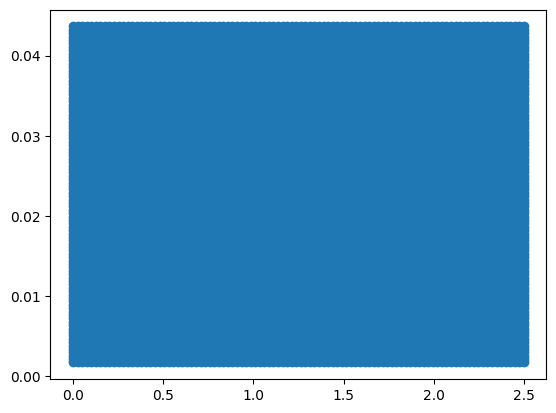

In [169]:
n = 100
Alt_size = Alt_list.size

M0 = np.linspace(0,2.5,n)
m_dot_f = np.linspace(.2,5,n) * m_dot_fR

M0, m_dot_f = np.meshgrid(M0,m_dot_f)

M0 = np.matrix.flatten(M0)
m_dot_f = np.matrix.flatten(m_dot_f)

plt.scatter(M0,m_dot_f)

j = 0

Alt = Alt_list[j]
T0 = T0_list[j]
P0 = P0_list[j]
rho0 = P0/(R*T0)
a0 = np.sqrt(gamma*R*T0)

In [170]:
n = 100
Alt_size = Alt.size

M0 = np.linspace(0,2.5,n)
m_dot_f = np.linspace(.2,5,n) * m_dot_fR

M0, m_dot_f = np.meshgrid(M0,m_dot_f)

M0 = np.matrix.flatten(M0)
m_dot_f = np.matrix.flatten(m_dot_f)

j = 3

Alt = Alt_list[j]
T0 = T0_list[j]
P0 = P0_list[j]
rho0 = P0/(R*T0)
a0 = np.sqrt(gamma*R*T0)

def eta_c_fit(Tt4):
    x = Tt4/Tt2
    a = -2.3219 
    b = 1.7094 
    c = -0.2897 
    d = 0.0155
    return a + b*x + c*x**2 + d*x**3

def corr_rpm_fit(pi_c):
    x = pi_c
    aa = 22352.47 
    bb = 3718.445 
    cc = -52.5576 
    dd = -1.0899
    return aa + bb*x + cc*x**2 + dd*x**3


Tt4_plot = np.empty(n**2)
rpm_plot = np.empty(n**2)
pi_c_plot = np.empty(n**2)


for i in range(n**2):
    u0 = M0[i] * np.sqrt(gamma*R*T0)
    
    m_dot_no_spill = rho0 * u0 * A1
    
    tau_r = 1+(gamma-1)/2 * M0[i]**2
    pi_r = tau_r**(gamma/(gamma-1))
    
    Tt0 = T0 * tau_r
    Pt0 = P0 * pi_r
    
    Tt2 = Tt0
    Pt2 = Pt0 * pi_d
    
    _tau_c = lambda tau_lambda: 1+(tau_lambda*T0/Tt0)*(1-tau_t)
    
    _pi_c = lambda tau_lambda: (1+eta_c_fit(tau_lambda*T0)*(_tau_c(tau_lambda)-1))**(gamma/(gamma-1))
    
    _m_dot = lambda tau_lambda: Gamma / np.sqrt(R) * A4 * (P0*pi_r*pi_d*_pi_c(tau_lambda)*pi_b)*1/(np.sqrt(tau_lambda*T0))
    
    _mdotf = lambda tau_lambda: _m_dot(tau_lambda)*(tau_lambda-tau_r*_tau_c(tau_lambda))/((h)/(Cp*T0)-tau_lambda)-m_dot_f[i]
    
    tau_lambda = scipy.optimize.fsolve(_mdotf,1)
    
    if tau_lambda == 1:
        tau_lambda = np.nan
    
    Tt4 = T0 * tau_lambda 
    
    
    
    tau_c = _tau_c(tau_lambda)
    pi_c = _pi_c(tau_lambda)
    tau_b = tau_lambda/(tau_r * tau_d * tau_c)
    m_dot_air = _m_dot(tau_lambda)
    corr_rpm = corr_rpm_fit(pi_c) * np.sqrt(Tt0/T0)
    #print(pi_c)
    
    
    
    
    
    # print(Tt4)
    eta_c = eta_c_fit(Tt4)
    
    Tt4_plot[i] = Tt4
    rpm_plot[i] = corr_rpm
    pi_c_plot[i] = pi_c
    
    if Tt4 > Tt4_max:
        Tt4_plot[i] = np.nan
        pi_c_plot[i] = np.nan
        rpm_plot[i] = np.nan
        continue
    
    if pi_c > pi_c_max or pi_c < pi_c_min:
        Tt4_plot[i] = np.nan
        pi_c_plot[i] = np.nan
        rpm_plot[i] = np.nan
        continue
   
    if corr_rpm > rpm_max or corr_rpm < 0:
        Tt4_plot[i] = np.nan
        pi_c_plot[i] = np.nan
        rpm_plot[i] = np.nan
        continue
    

C:\Users\rjk12\AppData\Local\Temp\ipykernel_31088\2813773826.py:64: RuntimeWarning: The iteration is not making good progress, as measured by the 
  improvement from the last ten iterations.
  tau_lambda = scipy.optimize.fsolve(_mdotf,1)
C:\Users\rjk12\AppData\Local\Temp\ipykernel_31088\2813773826.py:87: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  Tt4_plot[i] = Tt4
C:\Users\rjk12\AppData\Local\Temp\ipykernel_31088\2813773826.py:88: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  rpm_plot[i] = corr_rpm
C:\Users\rjk12\AppData\Local\Temp\ipykernel_31088\2813773826.py:89: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is

In [171]:
min(pi_c_plot)

nan

In [172]:
Tt4_plot = np.reshape(Tt4_plot,(n,n))
rpm_plot = np.reshape(rpm_plot,(n,n))
pi_c_plot = np.reshape(pi_c_plot,(n,n))
M0 = np.reshape(M0,(n,n))
m_dot_f = np.reshape(m_dot_f,(n,n))
#plt.contourf(M0,m_dot_f,Tt4_plot)

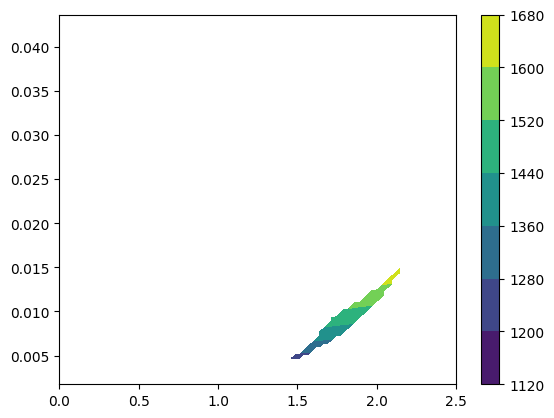

In [173]:
fig = plt.figure(1)
ax = plt.axes()
cp = ax.contourf(M0,m_dot_f,Tt4_plot)
fig.colorbar(cp)
plt.show()

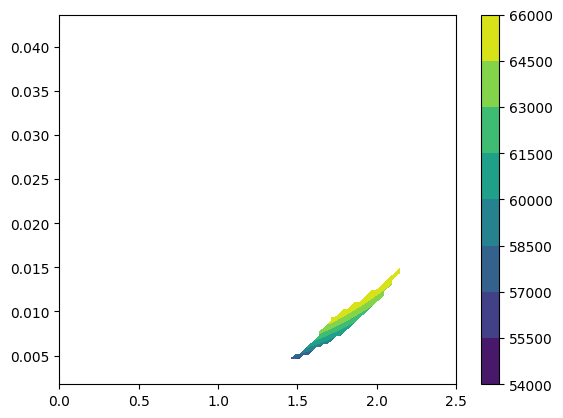

In [174]:
fig = plt.figure(2)
ax = plt.axes()
cp = ax.contourf(M0,m_dot_f,rpm_plot,cmap='viridis')

fig.colorbar(cp)
plt.show()

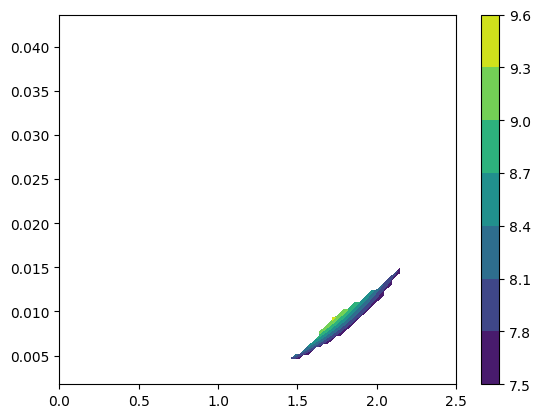

In [175]:
fig = plt.figure(3)
ax = plt.axes()
cp = ax.contourf(M0,m_dot_f,pi_c_plot)


fig.colorbar(cp)
plt.show()